In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('student_tea_snacks.csv')

# Display the first 5 rows
df.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [2]:
# Count occurrences of each tea type
tea_counts = df['tea_type'].value_counts()
print(tea_counts)

print("\nMost Preferred Tea Type:", tea_counts.idxmax())

tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64

Most Preferred Tea Type: Green


In [3]:
# Group by gender and calculate average cups per day
avg_cups_gender = df.groupby('gender')['cups_per_day'].mean()
print(avg_cups_gender.round(2))

gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64


snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


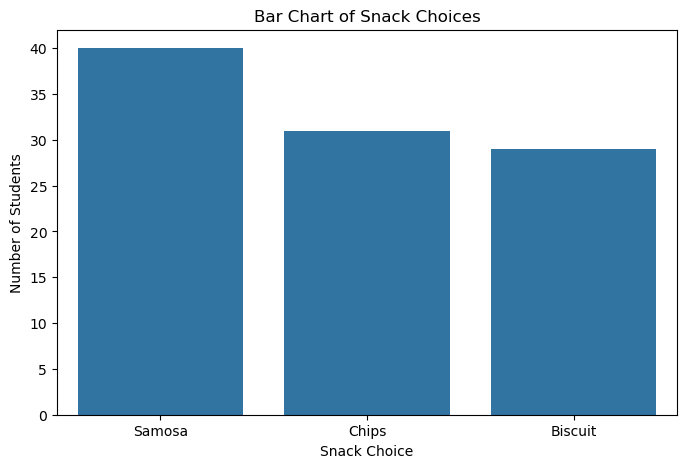

In [4]:
# Count snack choices
snack_counts = df['snack_choice'].value_counts()
print(snack_counts)

# Plot bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=snack_counts.index, y=snack_counts.values)
plt.title('Bar Chart of Snack Choices')
plt.xlabel('Snack Choice')
plt.ylabel('Number of Students')
plt.show()

In [5]:
# Compare whether students prefer tea ('Yes' vs 'No') across age groups
tea_pref_age = pd.crosstab(df['age_group'], df['prefers_tea'])
print("Tea Preference (Yes/No) by Age Group:\n", tea_pref_age)

# Compare specific tea types across age groups
tea_type_age = pd.crosstab(df['age_group'], df['tea_type'])
print("\nTea Type by Age Group:\n", tea_type_age)

Tea Preference (Yes/No) by Age Group:
 prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16

Tea Type by Age Group:
 tea_type   Black  Doodh Patti  Green
age_group                           
18-20          9           11     13
21-23          9            6      5
24-26          5            8     11


In [6]:
# 1. Students who answered 'No' to prefers_tea
no_pref = (df['prefers_tea'] == 'No').sum()
print("Students with prefers_tea == 'No':", no_pref)

# 2. Students who drink 0 cups per day
zero_cups = (df['cups_per_day'] == 0).sum()
print("Students with cups_per_day == 0:", zero_cups)

# 3. Students with no tea_type listed (NaN / None)
no_tea_type = df['tea_type'].isna().sum()
print("Students with missing tea_type (None):", no_tea_type)

Students with prefers_tea == 'No': 49
Students with cups_per_day == 0: 13
Students with missing tea_type (None): 23
